# Scaling up: 8-task multi-MNIST

Does our method still keep the tasks apart when there are many of them, and how close does it get to the ideal
connectivity? The experiment of `05_multi_mnist.ipynb`, scaled from 2 to 8 tasks with 10 hidden units per task.

**Problem.** As in `05_multi_mnist.ipynb`, with 8 tasks: each sample concatenates 8 independently drawn 14×14 MNIST
training images (per-pixel centered, one global scale), and each task's target is its own image's label. Every 250
steps, one task (chosen at random) gets a new random mapping from digits to labels, so each task changes about every
2000 steps, as in the 2-task problem. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 1568 inputs → 80 LTU hidden units → 80 linear outputs (8 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learners.** As in `05_multi_mnist.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner trains both networks, and ours also trains the fully connected network with the simple generate and test
of `05_multi_mnist.ipynb`, except that every 100k steps it resets the 4 hidden units with the smallest mean $|$output
weight$|$ at once (output weights 0, input weights $U(-\alpha_0, \alpha_0)$, step-sizes $\alpha_0$, zero Autostep
traces, running means at their initial values). 1M steps and 30 seeds; seed $s$ gives every run the same initial-weight
draw, images and label changes. (Shadow weights are explored in `follow_ups/shadow_weights.ipynb`.)

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**, ours learns not to mix: fully connected, ours is at most 1 percentage point below ours with ideal
  connectivity.
- **H2**, mixing is a real cost: fully connected, standard Autostep is more than 1 percentage point below standard
  Autostep with ideal connectivity.
- **H3**, generate and test helps: with it, ours fully connected is more than 1 percentage point above itself without
  it.

**Diagnostics**, fixed in advance: path purity and allocation over training, as in `05_multi_mnist.ipynb`. Allocation
is $(1 - \text{largest task's share of units}) / (1 - 1/8)$: 1 when every task has 10 units, 0 when all 80 feed one
task.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 8
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 500                      # each window records its mean loss, accuracy, path purity and allocation
BATCH = 15                           # networks trained at once; past about 20 they spill out of the GPU's cache and
                                     # every step gets several times slower

# --- Generate and test ---
RESET_PERIOD = 100_000               # steps between resets ...
N_RESET = 4                          # ... of this many units at once, those with the smallest mean |output weight|

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 15,680 weights, w2 800 weights
fully connected: w1 125,440 weights, w2 6,400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden = masks['w1'].shape[0]
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss
    # and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    learner = learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope)
    return learner, loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
WINDOW = NUM_STEPS // N_WINDOWS      # steps per window


def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def reset_units(learner, units, key, masks):
    # The hidden units marked in `units` start over as new units: their weights, step-sizes, Autostep traces and running
    # means are set to those of a freshly initialized network (output weights 0, input weights
    # U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    fresh = init_learner(key, masks, ours=True)
    parts = {'w1': units[:, None], 'w2': jnp.append(units, False)[None, :]}         # their rows of w1, columns of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    return learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(units, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(units[:, None], fresh.hidden_slope, learner.hidden_slope))


def train(key, stream, masks, ours, reset_period=None):
    # Step 1 on its own, then NUM_STEPS online steps in windows. With `reset_period` (a multiple of WINDOW), generate
    # and test runs at the end of every window that ends on a multiple of it: the N_RESET hidden units with the smallest
    # mean |output weight| start over as new units. Returns the mean loss and accuracy of every window, and the path
    # purity and allocation at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours)
        return (learner, stream), (loss, accuracy)

    def window(carry, index):
        (learner, stream), (loss, accuracy) = jax.lax.scan(one_step, carry, length=WINDOW)
        if reset_period is not None:
            utility = jnp.abs(learner.w['w2'][:, :-1]).mean(0)
            units = jnp.argsort(jnp.argsort(utility)) < N_RESET                  # the N_RESET lowest
            due = (index + 1) * WINDOW % reset_period == 0
            reset = reset_units(learner, units, jax.random.fold_in(key, index), masks)
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
        w = learner.w
        return (learner, stream), {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                                   'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks, ours), x, labels, masks, ours)[0]
    return jax.lax.scan(window, (learner, stream), jnp.arange(N_WINDOWS))[1]


def seeds(n):
    # The first n seeds' init keys and streams. Seed s uses init key s and stream s in every run, so runs are paired.
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)[:n]
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS)[:n])


def batched(fn, *args):
    # `fn` vmapped over the leading axis of every argument and jitted, run on BATCH entries at a time. Returns the
    # concatenated results as numpy arrays.
    f = jax.jit(jax.vmap(fn))
    n = len(jax.tree.leaves(args)[0])
    chunks = [f(*jax.tree.map(lambda a: a[i:i + BATCH], args)) for i in range(0, n, BATCH)]
    return jax.tree.map(lambda *c: np.concatenate(c), *chunks)


def run(network, ours, reset_period=None):
    # Trains our learner (or standard Autostep) on `network` (a key of MASKS) on every seed, with generate and test as
    # in train(). Returns per-seed records: loss, accuracy, purity and allocation (seed, window).
    return batched(lambda key, stream: train(key, stream, MASKS[network], ours, reset_period), *seeds(N_SEEDS))

## Results

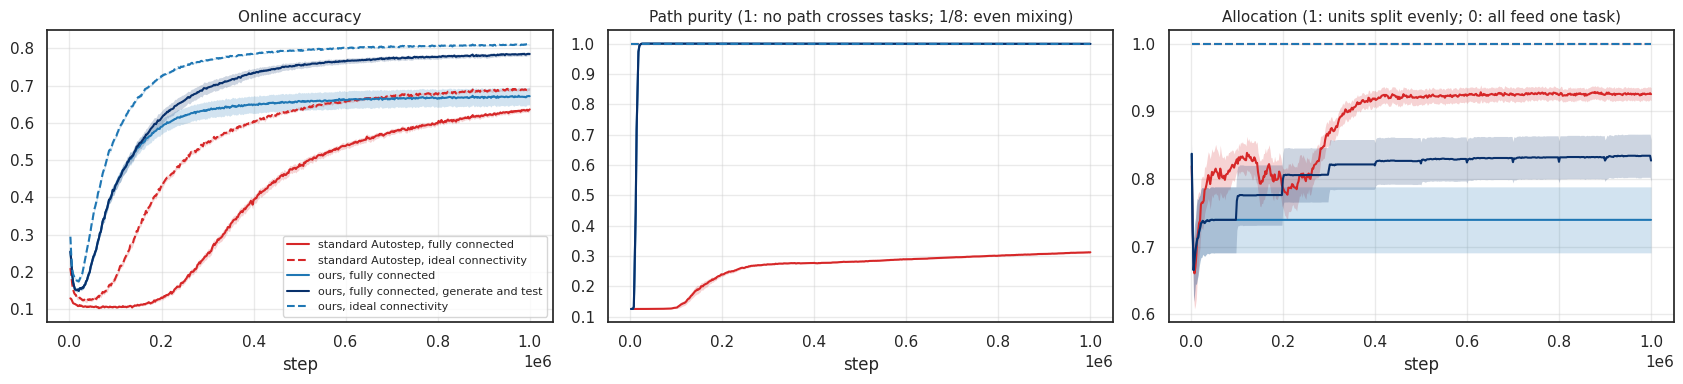

standard Autostep, fully connected         online accuracy 62.83%
standard Autostep, ideal connectivity      online accuracy 68.84%
ours, fully connected                      online accuracy 67.02%
ours, fully connected, generate and test   online accuracy 78.34%
ours, ideal connectivity                   online accuracy 80.97%
H1, ours, fully connected vs ours, ideal connectivity: -14.0 points (± 2.4): failed
H2, standard Autostep, fully connected vs standard Autostep, ideal connectivity: -6.0 points (± 0.5): held
H3, ours, fully connected vs ours, fully connected, generate and test: -11.3 points (± 2.0): held


In [7]:
window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def plot_runs(runs, colors, dashed=()):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds), drawn in
    # `colors[label]`, and dashed for the labels in `dashed`.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, title) in zip(axes, [('accuracy', 'Online accuracy'),
                                       ('purity', f'Path purity (1: no path crosses tasks; 1/{N_TASKS}: even mixing)'),
                                       ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference, claim) the per-seed gap of `label` to
    # `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within' ACCURACY_TOLERANCE of it, or
    # more than that 'below' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}){verdict}')


runs = {'standard Autostep, fully connected': run('fully connected', ours=False),
        'standard Autostep, ideal connectivity': run('ideal connectivity', ours=False),
        'ours, fully connected': run('fully connected', ours=True),
        'ours, fully connected, generate and test': run('fully connected', ours=True, reset_period=RESET_PERIOD),
        'ours, ideal connectivity': run('ideal connectivity', ours=True)}
# Color by learner, generate and test in a darker blue; dashed for the ideal connectivity.
colors = {label: 'tab:blue' if label.startswith('ours') else 'tab:red' for label in runs}
plot_runs(runs, colors | {'ours, fully connected, generate and test': '#08306b'},
          dashed=[label for label in runs if label.endswith('ideal connectivity')])
report(runs, [('H1', 'ours, fully connected', 'ours, ideal connectivity', 'within'),
              ('H2', 'standard Autostep, fully connected', 'standard Autostep, ideal connectivity', 'below'),
              ('H3', 'ours, fully connected', 'ours, fully connected, generate and test', 'below')])

## Results

- **H1 failed.** Fully connected, ours reaches 67.0% online accuracy against 81.0% with the ideal connectivity:
  −14.0 points (± 2.4, 2 SE over paired seeds), far more than with 2 tasks (−5.0).
- **H2 held.** Fully connected, standard Autostep is −6.0 points (± 0.5): 62.8% against 68.8%, also far more than with
  2 tasks (−1.2). It stays near chance (about 11%) for the first 150k steps and is still rising at 1M steps (+1.7
  points over the previous 10% of training), so this gap may shrink with longer training.
- Ours beats standard Autostep on both networks, by 4.2 points fully connected and by 12.1 with ideal connectivity.
- **H3 held.** The simple generate and test lifts ours fully connected to 78.3%, +11.3 points (± 2.0), leaving 2.6
  points to the ideal network, and it is still rising at 1M steps.
- **Diagnostics.** Ours' path purity reaches 1 within about 25k steps in every seed: even with 8 tasks, ours never
  mixes them. Standard Autostep does: its purity stays at 1/8 (even mixing) for the first 100k steps and climbs only
  to about 0.31 by 1M steps. Ours' shortfall is allocation again. Without generate and test, its allocation settles at
  about 0.74 by 50k steps and never changes, against about 0.93 for standard Autostep (from about 350k steps on); with
  generate and test, it climbs in a step at each reset, mostly at the first three (100k to 300k steps), to about
  0.83.